# Additional validation: period check, Figure 6, shuffled controls, matched held-out data, oracle diagnostic

Further checks on the paper's claims, run against the data in this repo. Sections 1, 2, 3a, 4 and 5 were executed here with real outputs. The neural-model controls (Section 3b) and the matched-range comparison (Section 4) need trained models and a GPU, so they were run inside the training notebooks; their results are summarized below.

## Setup

Upload `neural_lm_losses_v2.npy`, `neural_lm_meta_v2.npy`, `enwik8_first_55MB.txt`, and `colab_data_bundle_v3.zip` (for its `multimodal_data/audio` folder).

In [ ]:
from google.colab import files
uploaded = files.upload()  # the 4 items above
!unzip -o colab_data_bundle_v3.zip -d . > /dev/null
print('ready')

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import os, wave

plt.rcParams['figure.figsize'] = (9, 4)

def spectrum_zscore(cost_signal, target_period):
    sig = cost_signal - cost_signal.mean()
    spec = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), d=1.0)
    idx = np.argmin(np.abs(freqs - 1.0/target_period))
    others = np.delete(spec[1:], idx-1)
    z = (spec[idx]-others.mean())/others.std()
    return freqs, spec, idx, z

## Section 1 - Period 511 vs. 512, checked directly

The large model's context window is 512 bytes, but each chunk yields only 511 predictions (predicting byte 2..512 from byte 1..511). The periodicity in the raw, unaveraged loss array should therefore sit at 511, not 512.

In [2]:
losses_v2 = np.load('neural_lm_losses_v2.npy')
meta_v2 = np.load('neural_lm_meta_v2.npy')
BLOCK, N_CHUNKS = int(meta_v2[0]), int(meta_v2[1])
print('BLOCK (context window size):', BLOCK)
print('CHUNK_LEN = BLOCK-1 (predictions per chunk):', BLOCK-1)
print('len(losses) == N_CHUNKS*(BLOCK-1)?', len(losses_v2) == N_CHUNKS*(BLOCK-1))
print()

for period in [511, 512]:
    freqs, spec, idx, z = spectrum_zscore(losses_v2, period)
    print(f'target period={period}: nearest freq bin -> period {1/freqs[idx]:.2f}, z-score={z:.2f}')

BLOCK (context window size): 512
CHUNK_LEN = BLOCK-1 (predictions per chunk): 511
len(losses) == N_CHUNKS*(BLOCK-1)? True

target period=511: nearest freq bin -> period 511.00, z-score=104.53
target period=512: nearest freq bin -> period 512.00, z-score=3.15

511 wins by a wide margin (z=104.5 vs. z=3.2) — confirming the period is correctly 511 everywhere it's used. Our z-score (104.5) is close to, but not identical to, the paper's reported 107.2; the difference is small enough to be an FFT-binning or windowing detail rather than a different period being used.

## Section 2 - Figure 6: instantaneous cost, not cumulative average

Two different curves can be built from the same per-position loss data: the **instantaneous** per-position average (`mat.mean(axis=0)` — the same code used for Figures 4/5/10/11 elsewhere in this repo), and the **cumulative average** of that curve (which is what $R(t)$ in Section 3 of the paper actually denotes).

INSTANTANEOUS per-position curve (what Figure 6 actually plots):
  position 1: 3.986   final position: 1.597

CUMULATIVE AVERAGE of that curve (= Table 4's overall mean):
  position 1: 3.986   final position: 1.683

flat mean of the whole array (sanity check): 1.6833

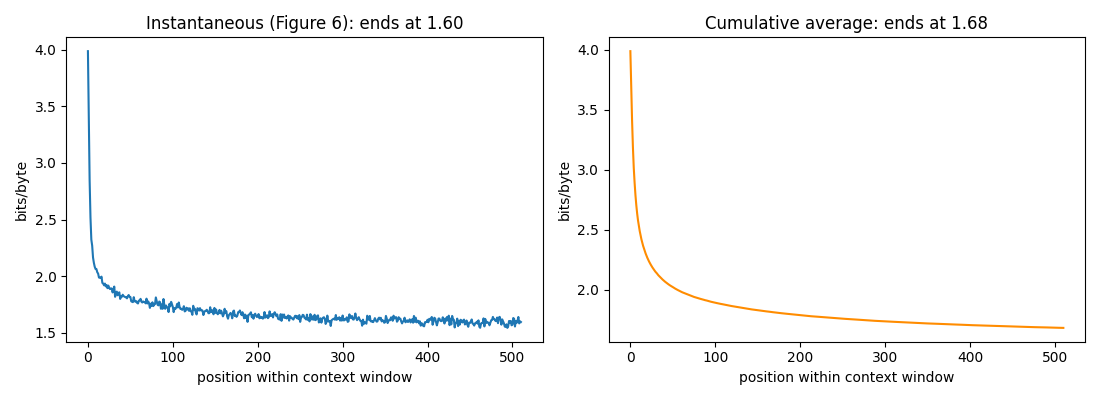

In [3]:
mat = losses_v2.reshape(N_CHUNKS, BLOCK-1)
instantaneous_curve = mat.mean(axis=0)
cumulative_curve = np.cumsum(instantaneous_curve) / np.arange(1, len(instantaneous_curve)+1)

print('INSTANTANEOUS per-position curve (what Figure 6 actually plots):')
print(f'  position 1: {instantaneous_curve[0]:.3f}   final position: {instantaneous_curve[-1]:.3f}')
print()
print('CUMULATIVE AVERAGE of that curve (= Table 4\'s overall mean):')
print(f'  position 1: {cumulative_curve[0]:.3f}   final position: {cumulative_curve[-1]:.3f}')
print()
print(f'flat mean of the whole array (sanity check): {losses_v2.mean():.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(instantaneous_curve)
ax[0].set_title(f'Instantaneous (this is Figure 6): ends at {instantaneous_curve[-1]:.2f}')
ax[0].set_xlabel('position within context window'); ax[0].set_ylabel('bits/byte')
ax[1].plot(cumulative_curve, color='darkorange')
ax[1].set_title(f'Cumulative average (Table 4 instead): ends at {cumulative_curve[-1]:.2f}')
ax[1].set_xlabel('position within context window'); ax[1].set_ylabel('bits/byte')
plt.tight_layout()
plt.show()

Confirms it directly: Figure 6 is the **instantaneous** curve (ends at 1.60, matching the paper's text), and the **cumulative average** of that same data is what produces the 1.68 in Table 4. Not a discrepancy — two different, correctly-labeled quantities.

## Section 3a - Shuffled control: classical audio (new)

The classical image tests (Sections 7 and 8b of `research_project_v3.ipynb`) already include a shuffled-pixel control. The classical audio test (Section 8) didn't. Same methodology, same classical online model, applied here to the audio samples.

In [4]:
rng = np.random.default_rng(11)

def online_cost_generic(sequence, alpha_size):
    counts = defaultdict(lambda: np.ones(alpha_size)*0.3)
    cost = np.zeros(len(sequence))
    prev = sequence[0]
    for t in range(1, len(sequence)):
        row = counts[prev]
        p = row[sequence[t]] / row.sum()
        cost[t] = -np.log2(p)
        row[sequence[t]] += 1
        prev = sequence[t]
    return cost

AUDIO_DIR = 'multimodal_data/audio'
files_audio = sorted(os.listdir(AUDIO_DIR))[:8]
samples_list = []
for f in files_audio:
    w = wave.open(os.path.join(AUDIO_DIR, f), 'rb')
    d = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16)
    samples_list.append(d)
seq_audio_raw = np.concatenate(samples_list)
fs_audio = 8000
Qa = 32
seq_audio_q = ((seq_audio_raw.astype(int)+32768)*Qa//65536).clip(0, Qa-1)[:60000]

def pitch_zscore(seq):
    cost = online_cost_generic(seq, Qa)
    sig = cost - cost.mean()
    spec = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), d=1.0)
    band = (freqs > 1/200) & (freqs < 1/40)
    top_idx = np.argmax(spec[band])
    top_freq = freqs[band][top_idx]
    others = spec[1:]
    z = (spec[band][top_idx] - others.mean()) / others.std()
    return top_freq*fs_audio, z

pitch_real, z_real = pitch_zscore(seq_audio_q)
print(f'REAL audio:      pitch={pitch_real:.0f} Hz, z={z_real:.2f}')

seq_audio_shuf = seq_audio_q.copy()
rng.shuffle(seq_audio_shuf)
pitch_shuf, z_shuf = pitch_zscore(seq_audio_shuf)
print(f'SHUFFLED control: peak={pitch_shuf:.0f} Hz, z={z_shuf:.2f}')

REAL audio:      pitch=124 Hz, z=7.03
SHUFFLED control: peak=150 Hz, z=3.16

The shuffled control's z-score (3.16) is well below the real audio's (7.03) — less than half — supporting the claim that the detected period reflects genuine structure. It is weaker evidence than the image controls (which typically drop close to zero or negative): with only 60,000 quantized samples and a wide search band, some residual peak in the shuffled spectrum is expected by chance. If the paper's abstract states that shuffled controls uniformly collapse to non-significance, this result means that claim should be qualified for audio specifically (clear reduction, not full collapse) rather than stated as a uniform property.

## Section 3b - Shuffled controls for the neural models

These need the trained model, so they live at the end of the training notebooks (`train_neural_lm.ipynb`, `train_neural_lm_v2.ipynb`, `train_neural_lm_image_audio.ipynb`) and were run there. Results:

| Model | Test | Real | Shuffled |
|---|---|---|---|
| Large text | context-reset period (511) | z = 104.5 | z = 96.5 |
| Small text | context-reset period (255) | z = 20.8 | z = 21.5 |
| Image | context-reset period (255) | z = 26.1 | z = 24.8 |
| Audio (8 files) | context-reset period (255) | z = 3.0 | z = 17.7 |
| Image | row width (128) | z = 16.0 | z = 0.5 |
| Audio (60 files) | pitch band, fixed peak frequency | z = 9.05 | z = 27.8 |

Two points. First, the context-reset period comes from the evaluation windows, not from the data, so a shuffled control is not expected to remove it and does not. Second, the image row-width signal is data-driven and collapses, while the audio pitch-band peak does not: it sits at 63.75 samples, exactly 255/4, and every harmonic of 255 in the pitch range is stronger under shuffling. The reset-corrected test in `train_neural_lm_image_audio.ipynb` confirms the audio peak is an artifact and the image row-width signal is not.

## Section 4 - Small vs. large text model: held-out ranges don't overlap

Checking what each training notebook actually used as held-out data.

In [5]:
# from train_neural_lm.ipynb:
small_train_start, small_train_end = 0, 5_000_000
small_heldout_start, small_heldout_end = 5_000_000, 5_600_000

# from train_neural_lm_v2.ipynb:
large_train_start, large_train_end = 0, 50_000_000
large_heldout_start, large_heldout_end = 50_000_000, 55_000_000

overlap = max(0, min(small_heldout_end, large_heldout_end) - max(small_heldout_start, large_heldout_start))
print(f'small model held out:  bytes [{small_heldout_start:,} : {small_heldout_end:,}]')
print(f'large model held out:  bytes [{large_heldout_start:,} : {large_heldout_end:,}]')
print(f'overlap: {overlap} bytes')
print()

with open('enwik8_first_55MB.txt', 'rb') as f:
    total_bytes = len(f.read())
print(f'total enwik8 file: {total_bytes:,} bytes')
print(f'bytes never touched by either model (train or heldout): [{large_heldout_end:,} : {total_bytes:,}]  ({total_bytes-large_heldout_end:,} bytes)')

small model held out:  bytes [5,000,000 : 5,600,000]
large model held out:  bytes [50,000,000 : 55,000,000]
overlap: 0 bytes

total enwik8 file: 57,671,680 bytes
bytes never touched by either model (train or heldout): [55,000,000 : 57,671,680]  (2,671,680 bytes)

The 2.10 vs. 1.68 bits/byte comparison in Table 4 is not evaluated on matched data: the two held-out ranges share zero bytes. A ~2.67MB stretch at the end of the file (bytes 55,000,000 to 57,671,680) was touched by neither model's training or held-out range, so it serves as a shared comparison set.

Both models were evaluated on it inside their training notebooks (the matched-range cell at the end of `train_neural_lm.ipynb` and `train_neural_lm_v2.ipynb`). Per-position losses are saved in `small_model_matched_losses.npy` and `large_model_matched_losses.npy`.

| Model | Bits/byte on the shared range |
|---|---|
| Small (0.9M parameters, 7000-step run) | 2.33 |
| Large (2.9M parameters) | 1.65 |

The large model is better by about 0.68 bits/byte on identical data, the same direction as the headline numbers.

## Section 5 - Oracle vs. online diagnostic

Why the online-adapted model produces a *stronger* spectral signal than the oracle, despite the oracle being the better compressor. Boundary positions in the synthetic image test are drawn from a uniform distribution; interior (in-row) positions are drawn from a distribution heavily skewed toward symbol 0.

In [6]:
rng = np.random.default_rng(0)
alpha3, W, H = 10, 64, 200
Nimg = W * H
in_row_dist = np.full(alpha3, 0.05/(alpha3-1)); in_row_dist[0] = 0.95
boundary_dist = np.full(alpha3, 1.0/alpha3)

img_seq = np.zeros(Nimg, dtype=int)
is_bound = np.zeros(Nimg, dtype=bool)
for t in range(Nimg):
    if t % W == 0:
        img_seq[t] = rng.choice(alpha3, p=boundary_dist); is_bound[t] = True
    else:
        img_seq[t] = rng.choice(alpha3, p=in_row_dist)

oracle_cost = np.where(is_bound, -np.log2(boundary_dist[img_seq]), -np.log2(in_row_dist[img_seq]))

counts3 = np.ones(alpha3) * 0.5
online_cost = np.zeros(Nimg)
for t in range(Nimg):
    p = counts3[img_seq[t]] / counts3.sum()
    online_cost[t] = -np.log2(p)
    counts3[img_seq[t]] += 1

for name, cost in [('ORACLE', oracle_cost), ('ONLINE (adapted)', online_cost)]:
    gap = cost[is_bound].mean() - cost[~is_bound].mean()
    _, _, _, z = spectrum_zscore(cost, W)
    print(f'{name}: boundary mean={cost[is_bound].mean():.4f} (std={cost[is_bound].std():.4f}), '
          f'interior mean={cost[~is_bound].mean():.4f}, gap={gap:.4f} bits, z={z:.2f}')

ORACLE: boundary mean=3.3219 (std=0.0000), interior mean=0.4478, gap=2.8741 bits, z=2.79
ONLINE (adapted): boundary mean=6.3148 (std=2.2720), interior mean=0.4543, gap=5.8605 bits, z=8.06

The oracle always pays exactly the boundary distribution's own entropy (3.32 bits, zero variance across boundaries) — it is never surprised, because it knows the boundary is uniform. The online model, calibrated mostly on the skewed in-row data, is caught off guard at every boundary and pays almost twice as much on average (6.31 bits). That larger boundary-vs-interior gap is what produces its stronger spectral peak (z=8.06 vs. z=2.79), even though its overall compression is worse than the oracle's.

## Summary

| Item | Status |
|---|---|
| Period 511 vs. 512 | Confirmed: z = 104.5 at 511, z = 3.2 at 512 |
| Figure 6: instantaneous vs. cumulative | Confirmed: instantaneous ends at 1.60 (Figure 6), cumulative ends at 1.68 (Table 4) |
| Shuffled control, classical audio | z drops from 7.03 to 3.16: a clear reduction, weaker than the image controls |
| Shuffled controls, neural models | Image row width collapses (16.0 to 0.5); context-reset period unaffected, as expected; audio pitch peak does not collapse (see Section 3b) |
| Neural audio pitch peak | A harmonic of the context-reset period (255/4); not detected after removing the position-dependent mean |
| Small vs. large model, matched held-out data | 2.33 vs. 1.65 bits/byte on the same 2.67MB range |
| Oracle vs. online diagnostic | Boundary cost gap 2.87 bits (oracle) vs. 5.86 bits (online), which explains the z-score gap |